# MAP: данные и валидация

Обзор обучающей выборки, разбиение на пять фолдов, MAP@3 и пример submission. Данные: [Kaggle](https://www.kaggle.com/competitions/map-charting-student-math-misunderstandings/data), локальная копия получена из [kaggle-map/data](https://huggingface.co/datasets/kaggle-map/data). Для повторного запуска локально положите три исходных CSV в папку `data` рядом с ноутбуком. В Kaggle подключите данные соревнования.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 90)
data_dir = Path("data") if Path("data/train.csv").exists() else Path("/kaggle/input/map-charting-student-math-misunderstandings")
train = pd.read_csv(data_dir / "train.csv", keep_default_na=False)
test = pd.read_csv(data_dir / "test.csv", keep_default_na=False)
sample = pd.read_csv(data_dir / "sample_submission.csv", keep_default_na=False)
print("train:", train.shape, "test:", test.shape, "sample:", sample.shape)

train: (36696, 7) test: (3, 5) sample: (3, 2)


## Обзор данных

In [2]:
display(train.head())
display(test.head())
train.info()
test.info()

,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation,Category,Misconception
0,0,31772,What fraction of the shape is not shaded? Give your answer in its simplest form. [Imag...,\( \frac{1}{3} \),0ne third is equal to tree nineth,True_Correct,NA
1,1,31772,What fraction of the shape is not shaded? Give your answer in its simplest form. [Imag...,\( \frac{1}{3} \),1 / 3 because 6 over 9 is 2 thirds and 1 third is not shaded.,True_Correct,NA
2,2,31772,What fraction of the shape is not shaded? Give your answer in its simplest form. [Imag...,\( \frac{1}{3} \),"1 3rd is half of 3 6th, so it is simplee to understand.",True_Neither,NA
3,3,31772,What fraction of the shape is not shaded? Give your answer in its simplest form. [Imag...,\( \frac{1}{3} \),1 goes into everything and 3 goes into nine,True_Neither,NA
4,4,31772,What fraction of the shape is not shaded? Give your answer in its simplest form. [Imag...,\( \frac{1}{3} \),1 out of every 3 isn't coloured,True_Correct,NA


,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation
0,36696,31772,What fraction of the shape is not shaded? Give your answer in its simplest form. [Imag...,\( \frac{1}{3} \),"I think that 1/3 is the answer, as it's the simplest form of 3/9."
1,36697,31772,What fraction of the shape is not shaded? Give your answer in its simplest form. [Imag...,\( \frac{3}{6} \),i think this answer is because 3 triangles are white and 6 triangle are blue.
2,36698,32835,Which number is the greatest?,\( 6.2 \),because the 2 makes it higher than the others.


<class 'pandas.DataFrame'>
RangeIndex: 36696 entries, 0 to 36695
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   row_id              36696 non-null  int64
 1   QuestionId          36696 non-null  int64
 2   QuestionText        36696 non-null  str  
 3   MC_Answer           36696 non-null  str  
 4   StudentExplanation  36696 non-null  str  
 5   Category            36696 non-null  str  
 6   Misconception       36696 non-null  str  
dtypes: int64(2), str(5)
memory usage: 2.0 MB
<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   row_id              3 non-null      int64
 1   QuestionId          3 non-null      int64
 2   QuestionText        3 non-null      str  
 3   MC_Answer           3 non-null      str  
 4   StudentExplanation  3 non-null      str  
dtypes: int64(2)

In [3]:
for name, df in [("train", train), ("test", test)]:
    print(f"\n{name}: вопросов {df.QuestionId.nunique()}, полных дубликатов {df.duplicated().sum()}")
    display(pd.DataFrame({"тип": df.dtypes, "пустых значений": df.replace("", np.nan).isna().sum()}))
print("Только в train:", sorted(set(train.columns) - set(test.columns)))
print("Только в test:", sorted(set(test.columns) - set(train.columns)))


train: вопросов 15, полных дубликатов 0


,тип,пустых значений
row_id,int64,0
QuestionId,int64,0
QuestionText,str,0
MC_Answer,str,0
StudentExplanation,str,0
Category,str,0
Misconception,str,0



test: вопросов 2, полных дубликатов 0


,тип,пустых значений
row_id,int64,0
QuestionId,int64,0
QuestionText,str,0
MC_Answer,str,0
StudentExplanation,str,0


Только в train: ['Category', 'Misconception']
Только в test: []


`NA` в `Misconception` обозначает отсутствие размеченного заблуждения и сохраняется как текст, а не пропуск.

## Распределение меток

In [4]:
labels = train.Category + ":" + train.Misconception.replace("", "NA")
category_counts = train.Category.value_counts()
label_counts = labels.value_counts()
misconception_counts = train.Misconception.replace("", "NA").value_counts()
display(pd.DataFrame({"число": category_counts, "доля, %": (category_counts / len(train) * 100).round(2)}))
print("Полных меток:", len(label_counts), "типов заблуждений без NA:", len(misconception_counts.drop("NA", errors="ignore")))
print("Все значения Misconception:")
display(misconception_counts.to_frame("число"))
print("Все полные метки:")
display(pd.DataFrame({"число": label_counts, "доля, %": (label_counts / len(train) * 100).round(3)}))
print(f"Максимум: {label_counts.max()}, минимум: {label_counts.min()}, меток с менее чем 5 примерами: {(label_counts < 5).sum()}")

,число,"доля, %"
Category,,
True_Correct,14802,40.34
False_Misconception,9457,25.77
False_Neither,6542,17.83
True_Neither,5265,14.35
True_Misconception,403,1.10
False_Correct,227,0.62


Полных меток: 65 типов заблуждений без NA: 35
Все значения Misconception:


,число
Misconception,
NA,26836
Incomplete,1454
Additive,929
Duplication,704
Subtraction,620
Positive,566
Wrong_term,558
Irrelevant,497
Wrong_fraction,418


Все полные метки:


,число,"доля, %"
True_Correct:NA,14802,40.337
False_Neither:NA,6542,17.828
True_Neither:NA,5265,14.348
False_Misconception:Incomplete,1446,3.940
False_Misconception:Additive,891,2.428
...,...,...
True_Misconception:Not_variable,1,0.003
True_Misconception:Whole_numbers_larger,1,0.003
True_Misconception:Longer_is_bigger,1,0.003
True_Misconception:Adding_across,1,0.003


Максимум: 14802, минимум: 1, меток с менее чем 5 примерами: 12


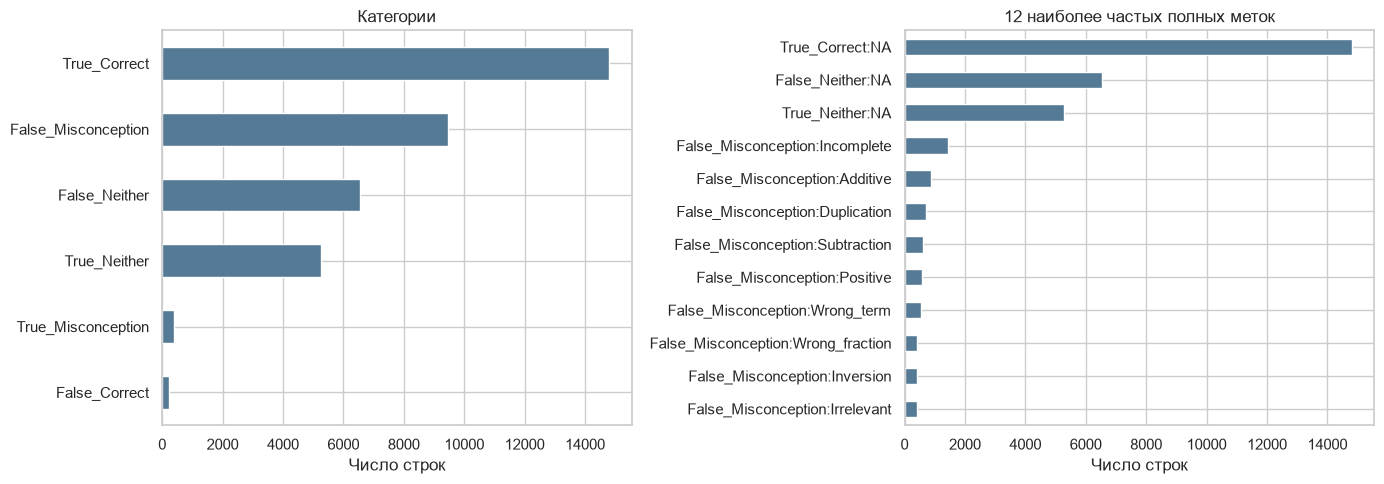

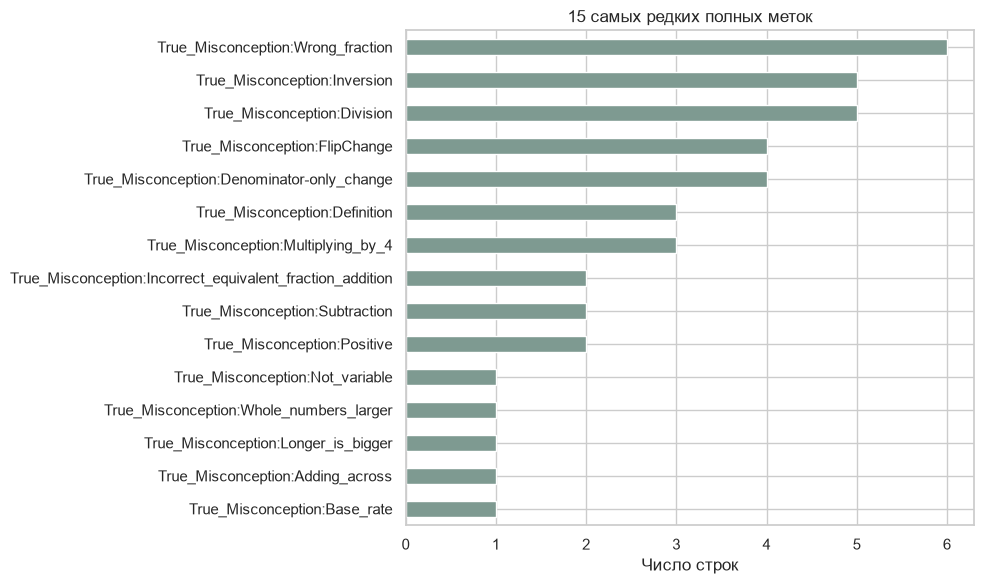

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
category_counts.sort_values().plot.barh(ax=axes[0], color="#557a95")
axes[0].set(title="Категории", xlabel="Число строк", ylabel="")
label_counts.head(12).sort_values().plot.barh(ax=axes[1], color="#557a95")
axes[1].set(title="12 наиболее частых полных меток", xlabel="Число строк", ylabel="")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
label_counts.tail(15).sort_values(ascending=False).plot.barh(ax=ax, color="#7e9a91")
ax.invert_yaxis()
ax.set(title="15 самых редких полных меток", xlabel="Число строк", ylabel="")
fig.tight_layout()
plt.show()

## Фолды

Стратифицируем по `Category`: у некоторых полных меток меньше пяти примеров. Доли категорий сравниваются внутри каждого фолда.

In [6]:
folds = train.copy()
folds["fold"] = -1
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for fold, (_, valid_idx) in enumerate(splitter.split(train, train.Category)):
    folds.loc[valid_idx, "fold"] = fold

assert len(folds) == len(train) and folds.fold.isin(range(5)).all()
print("Размер фолдов:")
display(folds.fold.value_counts().sort_index().to_frame("строк"))
print("Категории по фолдам, %:")
display((pd.crosstab(folds.fold, folds.Category, normalize="index") * 100).round(2))
label_by_fold = pd.crosstab(labels, folds.fold).reindex(columns=range(5), fill_value=0)
print("Полные метки по фолдам:")
display(label_by_fold)
print("Метки, отсутствующие хотя бы в одном фолде:", (label_by_fold.eq(0).any(axis=1)).sum())
folds.to_csv("train_folds.csv", index=False)

Размер фолдов:


,строк
fold,
0,7340
1,7339
2,7339
3,7339
4,7339


Категории по фолдам, %:


Category,False_Correct,False_Misconception,False_Neither,True_Correct,True_Misconception,True_Neither
fold,,,,,,
0,0.63,25.76,17.83,40.34,1.09,14.35
1,0.61,25.77,17.84,40.35,1.09,14.35
2,0.61,25.78,17.82,40.33,1.10,14.35
3,0.61,25.78,17.82,40.33,1.10,14.35
4,0.63,25.77,17.82,40.33,1.10,14.35


Полные метки по фолдам:


fold,0,1,2,3,4
row_0,,,,,
False_Correct:NA,46,45,45,45,46
False_Misconception:Adding_across,49,64,56,69,68
False_Misconception:Adding_terms,21,17,22,25,12
False_Misconception:Additive,174,182,184,171,180
False_Misconception:Base_rate,6,2,2,6,6
...,...,...,...,...,...
True_Misconception:WNB,0,3,2,2,1
True_Misconception:Whole_numbers_larger,0,0,1,0,0
True_Misconception:Wrong_fraction,1,0,2,0,3


Метки, отсутствующие хотя бы в одном фолде: 24


Проверим точные совпадения объяснений между фолдами. Одинаковый текст не обязательно означает одного ученика, но может завысить оценку при валидации.

In [7]:
explanations = folds.loc[folds.StudentExplanation.ne("")]
folds_per_text = explanations.groupby("StudentExplanation").fold.nunique()
repeated_texts = folds_per_text[folds_per_text > 1].index
cross_fold_rows = explanations.StudentExplanation.isin(repeated_texts).sum()
print("Разных объяснений, встречающихся в нескольких фолдах:", len(repeated_texts))
print("Строк с такими объяснениями:", cross_fold_rows)
print("Всего строк с повторяющимся объяснением:", explanations.StudentExplanation.duplicated(keep=False).sum())

Разных объяснений, встречающихся в нескольких фолдах: 546
Строк с такими объяснениями: 1402
Всего строк с повторяющимся объяснением: 1629


## MAP@3

Для одной правильной метки учитывается первое совпадение в тройке. Повторное предсказание не добавляет баллов.

In [8]:
def map_at_3(y_true, y_pred):
    if len(y_true) != len(y_pred) or len(y_true) == 0:
        raise ValueError("Нужны непустые списки одинаковой длины")
    scores = []
    for true, predictions in zip(y_true, y_pred):
        if len(predictions) != 3:
            raise ValueError("Для каждой строки нужны три предсказания")
        score = 0.0
        for rank, prediction in enumerate(predictions, start=1):
            if prediction == true:
                score = 1 / rank
                break
        scores.append(score)
    return float(np.mean(scores))

assert map_at_3(["a"], [["a", "b", "c"]]) == 1
assert map_at_3(["a"], [["b", "a", "c"]]) == 0.5
assert np.isclose(map_at_3(["a"], [["b", "c", "a"]]), 1 / 3)
assert map_at_3(["a"], [["b", "c", "d"]]) == 0
assert np.isclose(map_at_3(["a"] * 4, [["a", "b", "c"], ["b", "a", "c"], ["b", "c", "a"], ["b", "c", "d"]]), (1 + 0.5 + 1/3) / 4)
assert map_at_3(["a"], [["b", "a", "a"]]) == 0.5
print("Проверки MAP@3 пройдены")

Проверки MAP@3 пройдены


## Пример submission

Это только проверка формата: для всех строк используются три самые частые метки train. Модель не обучалась.

In [9]:
display(sample)
top_labels = label_counts.head(3).index.tolist()
submission = pd.DataFrame({"row_id": test.row_id, "Category:Misconception": " ".join(top_labels)})
assert submission.columns.tolist() == sample.columns.tolist()
assert len(submission) == len(test) and submission.row_id.equals(test.row_id)
assert submission["Category:Misconception"].str.split().map(len).eq(3).all()
assert all(label in label_counts.index and ":" in label for label in top_labels)
assert submission["Category:Misconception"].ne("").all()
assert sample.row_id.equals(test.row_id)
submission.to_csv("submission.csv", index=False)
display(submission)
print("Формат и порядок row_id проверены")

,row_id,Category:Misconception
0,36696,True_Correct:NA False_Neither:NA False_Misconception:Incomplete
1,36697,True_Correct:NA False_Neither:NA False_Misconception:Incomplete
2,36698,True_Correct:NA False_Neither:NA False_Misconception:Incomplete


,row_id,Category:Misconception
0,36696,True_Correct:NA False_Neither:NA True_Neither:NA
1,36697,True_Correct:NA False_Neither:NA True_Neither:NA
2,36698,True_Correct:NA False_Neither:NA True_Neither:NA


Формат и порядок row_id проверены


## Выводы

In [10]:
top_cat = category_counts.index[0]
rare = label_counts[label_counts < 5]
missing_labels = label_by_fold.eq(0).any(axis=1).sum()
cat_shares = pd.crosstab(folds.fold, folds.Category, normalize="index") * 100
max_spread = (cat_shares.max() - cat_shares.min()).max()
display(Markdown(f"""- Самая частая категория: **{top_cat}**, {category_counts.iloc[0]:,} строк ({category_counts.iloc[0] / len(train):.1%}). Всего категорий: {len(category_counts)}.
- Полных меток: {len(label_counts)}. Самая частая, **{label_counts.index[0]}**, встречается {label_counts.iloc[0]:,} раз ({label_counts.iloc[0] / len(train):.1%}); минимум: {label_counts.min()}. Меток с менее чем 5 примерами: {len(rare)}.
- Примеры самых редких меток: {', '.join(f'{name} ({count})' for name, count in label_counts.tail(3).items())}.
- В разных фолдах встречаются {len(repeated_texts):,} различных одинаковых объяснений ({cross_fold_rows:,} строк). Это возможный источник утечки и оптимистичной оценки.
- Доли категорий по фолдам различаются максимум на {max_spread:.2f} процентного пункта. Разбиение подходит для базового сравнения, но {missing_labels} полных меток отсутствуют хотя бы в одном фолде; качество редких меток нужно оценивать осторожно."""))

- Самая частая категория: **True_Correct**, 14,802 строк (40.3%). Всего категорий: 6.
- Полных меток: 65. Самая частая, **True_Correct:NA**, встречается 14,802 раз (40.3%); минимум: 1. Меток с менее чем 5 примерами: 12.
- Примеры самых редких меток: True_Misconception:Longer_is_bigger (1), True_Misconception:Adding_across (1), True_Misconception:Base_rate (1).
- В разных фолдах встречаются 546 различных одинаковых объяснений (1,402 строк). Это возможный источник утечки и оптимистичной оценки.
- Доли категорий по фолдам различаются максимум на 0.02 процентного пункта. Разбиение подходит для базового сравнения, но 24 полных меток отсутствуют хотя бы в одном фолде; качество редких меток нужно оценивать осторожно.